# Customer Churn Prediction

## Project Overview

Customer churn occurs when customers stop using a company's products or services.

In this project, we analyze the Telco Customer Churn dataset to understand the factors responsible for customer churn and develop machine learning models to predict customers who are likely to leave.

## Objectives

1. Analyze customer churn patterns.
2. Clean and preprocess the dataset.
3. Perform exploratory data analysis.
4. Train and compare machine learning algorithms.
5. Optimize the model with a focus on recall.
6. Develop a Streamlit application for churn prediction.
7. Provide business recommendations to improve customer retention.

## Technologies Used

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab
- Streamlit
- GitHub

In [91]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


Load the CSV dataset

In [92]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


Check the first five rows of the dataset

In [93]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Check dataset dimensions

In [94]:
print("Shape:", df.shape)

Shape: (7043, 21)


Check data types

In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Check data types

In [96]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Check duplicates

In [97]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Check statistical information

In [98]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Machine learning algorithms need numerical values for numerical calculations. We cannot properly use a column containing text and blank spaces as a numerical feature.
 Convert TotalCharges into numeric

In [99]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [100]:
print(df["TotalCharges"].dtype)

print("Missing TotalCharges:",
      df["TotalCharges"].isnull().sum())

float64
Missing TotalCharges: 11


remove these 11 lines

In [101]:
df = df.dropna(subset=["TotalCharges"])

These customers had no recorded total charges so we excluded their incomplete records rather than invent values

In [102]:
print(df.shape)
print(df["TotalCharges"].isnull().sum())

(7032, 21)
0


Remove customerID

In [103]:
df= df.drop("customerID", axis=1)

In [104]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Now, Check the cleaned dataset

In [105]:
print("Final shape:", df.shape)

print("Missing values:",
      df.isnull().sum().sum())

print("Duplicates:",
      df.duplicated().sum())

Final shape: (7032, 20)
Missing values: 0
Duplicates: 22


In [106]:
print(df["Churn"].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


creating a graph for the churn

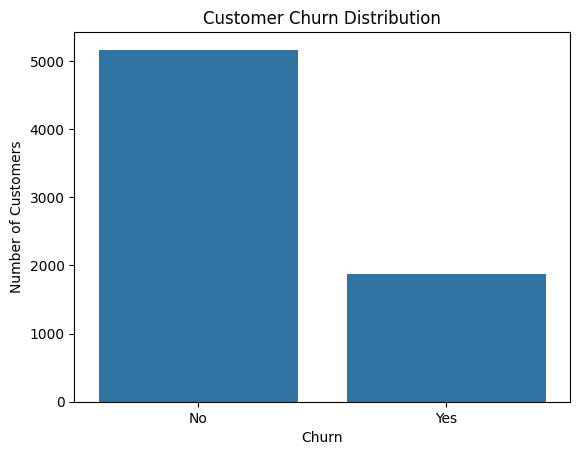

In [107]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

Churn by contract

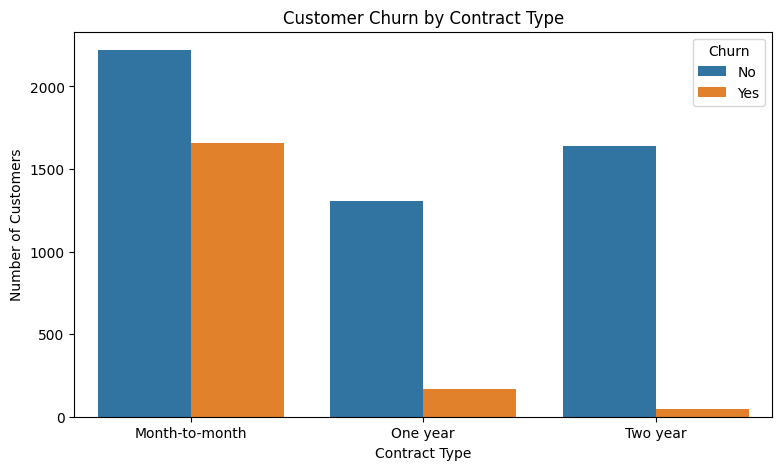

In [108]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [109]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


Interpretation:

Customers with month-to-month contracts tend to leave more frequently than customers with longer contracts.

Churn by tenure

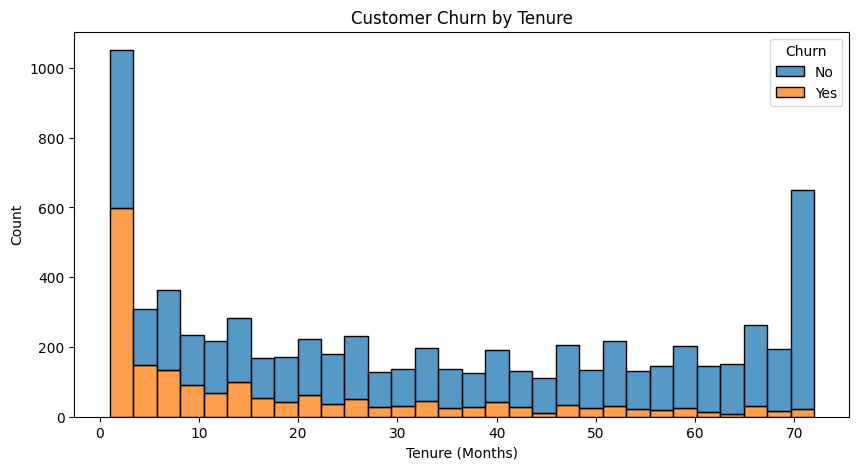

In [110]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    multiple="stack",
    bins=30
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure (Months)")

plt.show()

Interpretation:

We want to investigate whether customers are more likely to leave during their first few months.

Churn by monthly charges

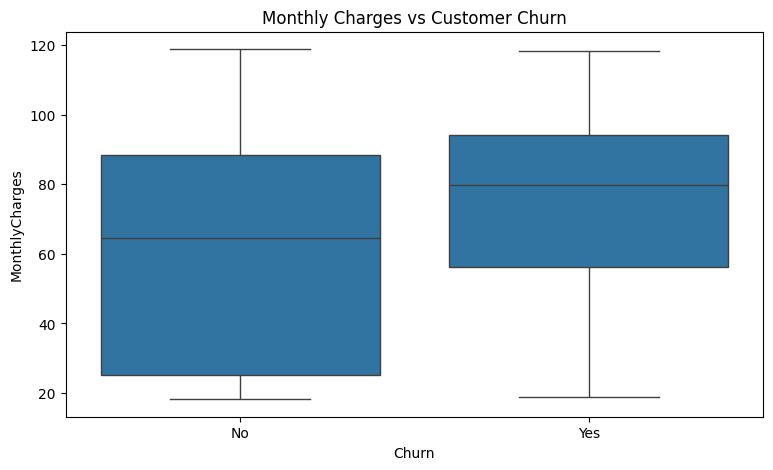

In [111]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")

plt.show()

Interpretation:

Compare the monthly bills of customers who stayed and customers who left.

This helps investigate whether higher monthly charges are associated with churn.

Churn by payment method

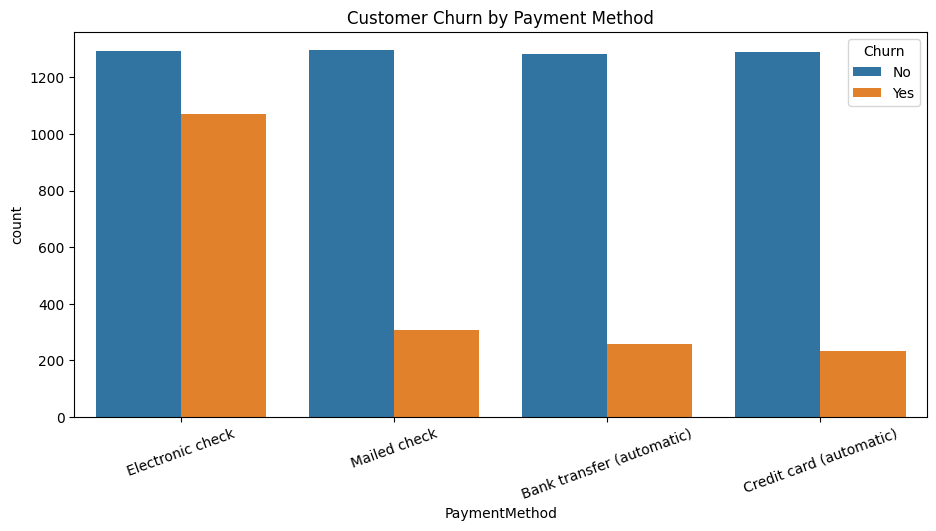

In [112]:
plt.figure(figsize=(11, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Customer Churn by Payment Method")
plt.xticks(rotation=20)

plt.show()

Calculate the percentage:

In [113]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


Interpretation:

Check whether electronic check users have a higher churn rate than other payment-method users.

Calculate the overall churn rate

In [114]:
churn_rate = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_rate)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


This gives us the percentage of customers who leave and stay.

-Prepare the data for machine learning
Now we move from data analysis to machine learning.

Features (X): Information used to make predictions, such as tenure, contract and monthly charges.



Target (y): What we want to predict, which is Churn.

Separate X and y

In [115]:
X = df.drop("Churn", axis=1)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

Split the dataset

In [116]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

Identify numerical and categorical columns

In [117]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


Numerical features: Values such as tenure and monthly charges.

Categorical features: Values such as contract type, gender and payment method.

Create preprocessing pipeline
We need two operations:
1. StandardScaler: Scales numerical features.
2. OneHotEncoder: Converts categorical features into numerical representations.

In [118]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

Train and compare three machine learning models

1. Logistic Regression: A classification algorithm that estimates the probability that a customer will leave.

2. Decision Tree: Makes predictions through a sequence of decision rules.

3. Random Forest: Combines multiple decision trees to make a prediction.

Create the models:

In [119]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

Train and evaluate the models
We will compare four evaluation metrics:
- Accuracy
- Precision
- Recall
- F1-score

Train all models:

In [120]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(
        y_test, predictions
    )

    precision = precision_score(
        y_test, predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7257     0.4901  0.7968    0.6069
1        Decision Tree    0.7214     0.4775  0.5107    0.4935
2        Random Forest    0.7818     0.6159  0.4759    0.5370


Visualize the comparison

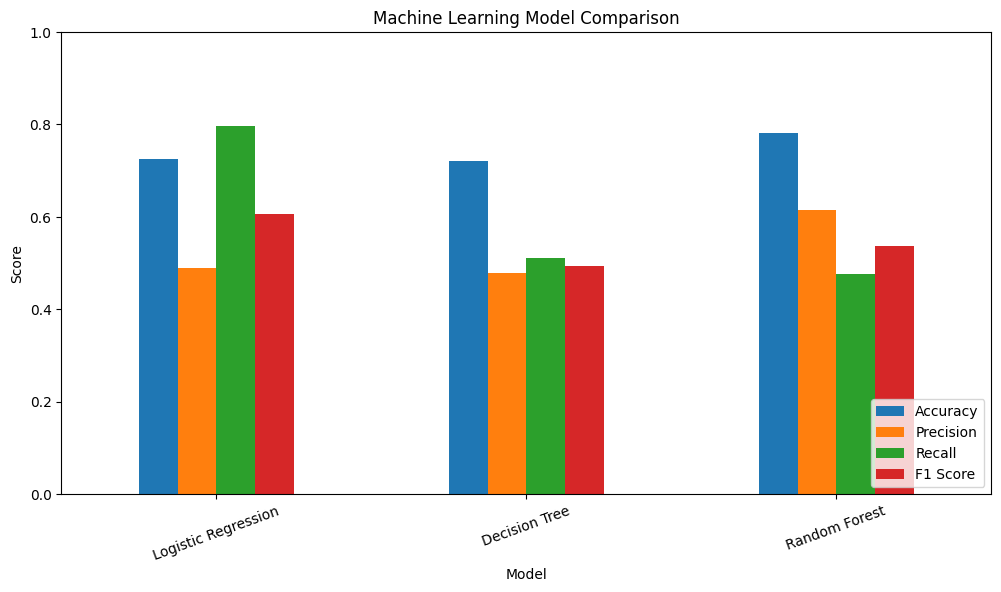

In [121]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.legend(loc="lower right")
plt.show()

A model with better recall can identify more customers who are actually going to leave, although this may result in more false alarms.

Hyperparameter tuning with GridSearchCV
Create the tuning pipeline:

In [122]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

Define parameter combinations

In [123]:
param_grid = {
    "classifier__n_estimators": [100, 200],

    "classifier__max_depth": [None, 10, 20],

    "classifier__min_samples_split": [2, 5],

    "classifier__min_samples_leaf": [1, 2]
}

Run GridSearchCV

In [124]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['SeniorCitizen',
                                                                          'tenure',
                                                                          'MonthlyCharges',
                                                                          'TotalCharges']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['gender',
                                                                          'Partner',
                                                                          'Dependents',
                                                                          'PhoneService',
                                                                          'MultipleLines',
                                                                          'InternetService',
                                                                          'OnlineSecurity',
                                                                          'OnlineBackup',
                                                                          'DeviceProtect...
                                                                          'StreamingMovies',
                                                                          'Contract',
                                                                          'PaperlessBilling',
                                                                          'PaymentMethod'])])),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced',
                                                               n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [None, 10, 20],
                         'classifier__min_samples_leaf': [1, 2],
                         'classifier__min_samples_split': [2, 5],
                         'classifier__n_estimators': [100, 200]},
             scoring='recall', verbose=1)

Get the best model

In [125]:
best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation Recall:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross Validation Recall:
0.7190635451505016


Now we have a tuned Random Forest model.

Final model evaluation
This is where we test our final model on data it has never seen during training.

Make predictions:

In [126]:
y_pred = best_model.predict(X_test)

Calculate evaluation metrics

In [127]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1 Score:",
      f1_score(y_test, y_pred))

Accuracy: 0.7611940298507462
Precision: 0.537109375
Recall: 0.7352941176470589
F1 Score: 0.6207674943566591


Confusion matrix:
A confusion matrix shows four outcomes.
Term              Meaning
True Negative:    	Correctly predicted customer stays
True Positive	:    Correctly predicted customer leaves
False Positive:  Predicted to leave but actually stays
False Negative:	 Predicted to stay but actually leaves

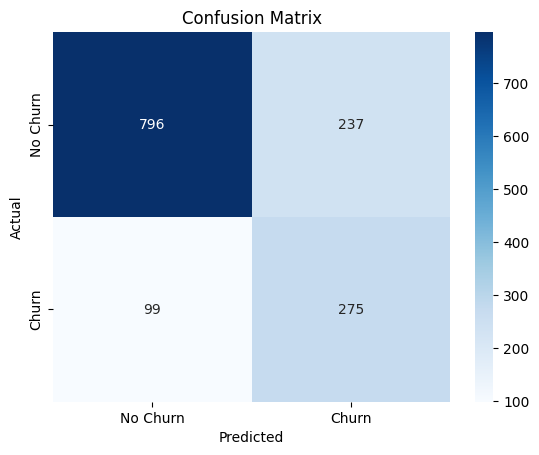

In [128]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Classification report

In [129]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.89      0.77      0.83      1033
       Churn       0.54      0.74      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.75      0.72      1407
weighted avg       0.80      0.76      0.77      1407



Recommendation 1: Improve month-to-month retention

Offer discounts or loyalty benefits to customers who are considering switching from month-to-month plans.

Recommendation 2: Improve first-year customer experience

Provide onboarding assistance and customer support to new customers, particularly during their first year.

Recommendation 3: Investigate electronic check payments

Investigate whether electronic check users experience payment difficulties or dissatisfaction. Make alternative payment methods easier to use.

Recommendation 4: Review high monthly bills

Analyze whether customers with higher monthly charges are receiving sufficient value and offer suitable packages.

# Conclusion

In this project, we analyzed the Telco Customer Churn
dataset to identify patterns associated with customer
churn.

We cleaned the dataset, performed exploratory data
analysis, trained three machine learning algorithms,
compared their performance, and tuned a model using
GridSearchCV.

Recall was prioritized because identifying customers
who are likely to leave is important for customer
retention.

Finally, we developed business recommendations based
on the findings to help the telecom company reduce
customer churn.

In [130]:
import joblib

joblib.dump(best_model, "churn_model.pkl")

['churn_model.pkl']

In [132]:
from google.colab import files

files.download("churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>